# Class

## We will discuss

- Options: payoff / profit
- Put-call parity
- 3 forms of pricing:
  - Binomial model
  - Black & Scholes
  - Monte-Carlo

## Call option

Right, not obligation, to **buy** the underlying at $T$ for $X$.

$$\max(S_T-X,0)$$

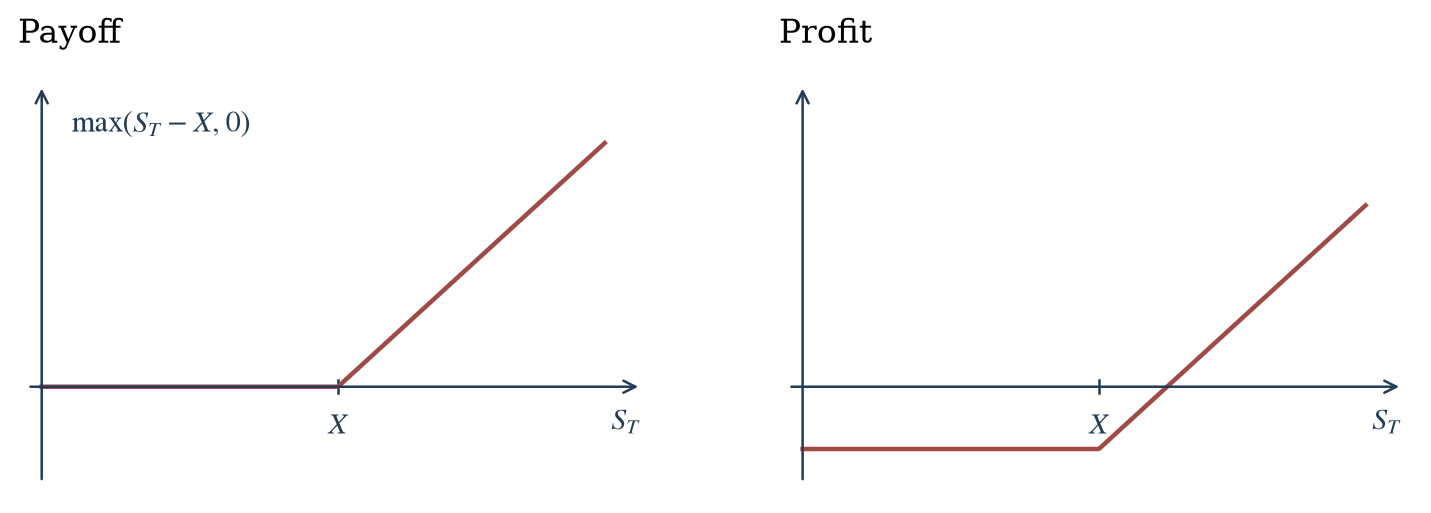

## Put option

Right, not obligation, to **sell** the underlying at $T$ for $X$.

$$\max(0,X-S_T)$$

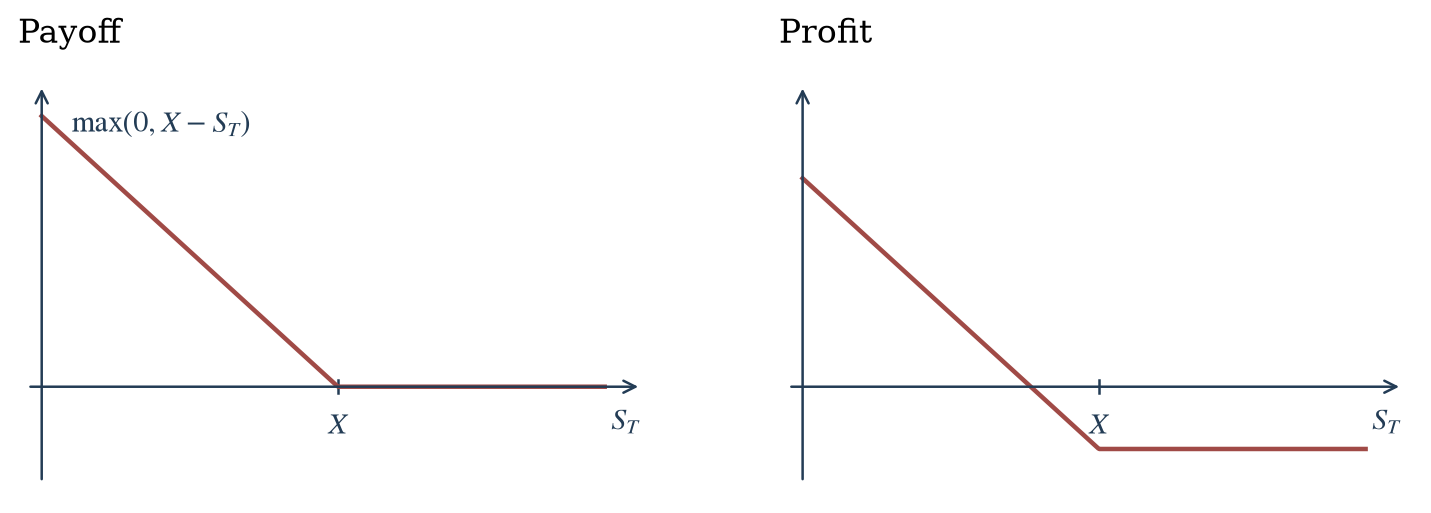

## Notation

| Symbol | Meaning |
|---|---|
| $S$ | Price of underlying |
| $S_0$ | Spot, price today |
| $S_T$ | Price at maturity |
| $X$ | Strike price, price at which you buy or sell through the option; sometimes $K$ |
| $T$ | Time to expiry |
| $C$ | Call price |
| $P$ | Put price |

## Premium

What's the difference between payoff & profit? What's the gap in the graphs?

**Premium.** If it did not exist, people could buy “infinite” options and some would be profitable. This would be arbitrage.

Main difference from options to futures: in futures, there are no premiums, but you **must** buy/sell; it is an obligation, unless you sell your position before maturity.

For an option to be a fair contract, the expected profit when buying it should be zero.

$$\pi=PV(E[\mathrm{payoff}])$$

$\pi$: premium.

## Moneyness

| | Call | Put |
|---|---|---|
| In the money | $S_T>X$ | $S_T<X$ |
| At the money | $S_T=X$ | $S_T=X$ |
| Out of the money | $S_T<X$ | $S_T>X$ |

## Put-call parity

We do present value by using $e^{-rT}$ when $r$ is a continuously compounded annual rate.

A bit more notation: usually, when calculating present values, future values, etc. in options and option pricing, the discount rate is usually a continuously compounded annual rate. When that is, the discount factor is:

$$e^{-rT}$$

Therefore, the present value of the strike price is:

$$PV(X)=Xe^{-rT}$$

With this, it can be shown, even though I won't, that:

$$S+P=C+Xe^{-rT}$$

This is what is known as put-call parity: an equation relating put & call prices.

## Arbitrage

| Call boundaries | From put-call parity | Put boundaries |
|---|:---:|---|
| $C>0$ | $\longrightarrow$ | $P>PV(X)-S$ |
| $C<S$ | $\longrightarrow$ | $P<PV(X)$ |
| $C>S-PV(X)$ | $\longrightarrow$ | $P>0$ |

Now that we know the limits of call & put prices, how do we actually price them?

We will see 3 methods:

- Binomial model: paper
- Black & Scholes: paper
- Monte Carlo: Python

## Binomial

First, we assume the option's payoff may take, at most, 2 values at maturity.

We can show that the payoffs of options can be replicated by the payoffs of a portfolio consisting of $\Delta$ shares of the underlying and $B$ units of a risk-free bond.

Due to the law of one price, the price of the option must be the same as the price of the portfolio: the **replicating portfolio**.

### 1. Build payoff trees

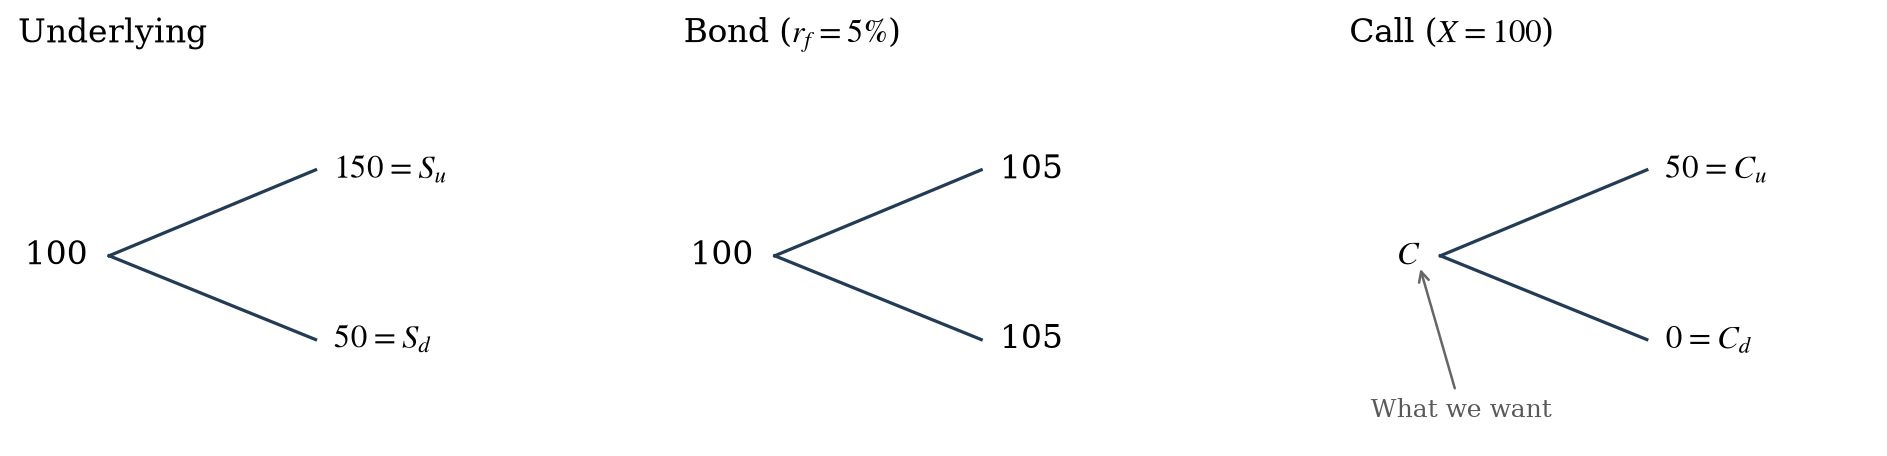

We know:

$$
\begin{cases}
S_u\Delta+BR=C_u\\
S_d\Delta+BR=C_d
\end{cases}
\quad\Longleftrightarrow\quad
\begin{cases}
150\Delta+1.05B=C_u=50\\
50\Delta+1.05B=C_d=0
\end{cases}
$$

$$R=1+r$$

### 2. Find delta and B

Solving this yields:

$$\Delta=\frac{C_u-C_d}{S_u-S_d},
\qquad B=\frac{1}{R}\frac{S_uC_d-S_dC_u}{S_u-S_d}$$

In the example:

$$\Delta=0.5,\qquad B=-23.81$$

### 3. Substitute in C = delta S0 + B

$$C=\Delta S_0+B$$

$$C=0.5(100)-23.81=26.19$$

If we don't care about $\Delta$ and $B$, but only about $C$, we have a faster way.

Let $u$ be the growth rate from $S_0$ to $S_u$:

$$u=\frac{150}{100}=1.5$$

Let $d$ be the growth rate from $S_0$ to $S_d$:

$$d=\frac{50}{100}=0.5$$

Then, the risk-neutral probability of an up move is:

$$q=\frac{R-D}{U-D}\in[0,1]$$

The risk-neutral probability of a down move is $1-q$.

### 1-period formula

$$C=\Delta S_0+B=\frac{1}{R}\left[qC_u+(1-q)C_d\right]$$

## 2-period model

$$q=\frac{R-D}{U-D}$$

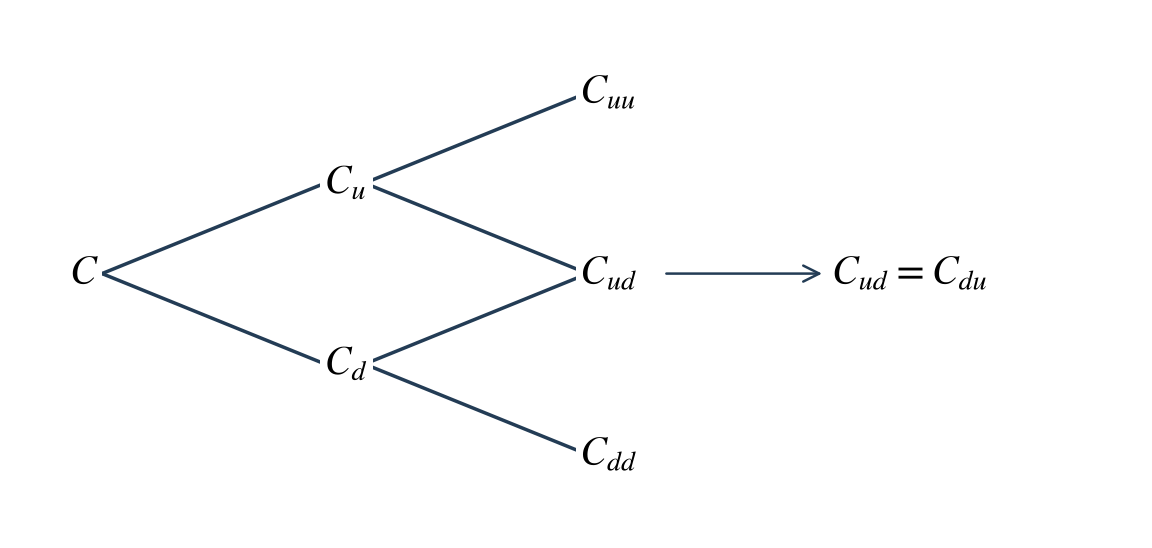

$$C_{ud}=C_{du}$$

Substitution in the 1-period formula:

$$C_u=\frac{1}{R}\left[qC_{uu}+(1-q)C_{ud}\right]$$

$$C_d=\frac{1}{R}\left[qC_{ud}+(1-q)C_{dd}\right]$$

Then:

$$C=\frac{1}{R^2}\left[q^2C_{uu}+2q(1-q)C_{ud}+(1-q)^2C_{dd}\right]$$

## Black-Scholes

The main idea behind this model is to split the binomial model into many small steps.

This then describes a continuous-price model, giving the value of a call:

$$C=\underbrace{S_0N(d_1)}_{\mathrm{shares\ worth}}
-\underbrace{Xe^{-rT}N(d_2)}_{\mathrm{financed\ partly\ by\ borrowing}}$$

New delta: $N(d_1)$.

$$d_1=\frac{\ln(S_0/X)+(r+\sigma^2/2)T}{\sigma\sqrt{T}},
\qquad d_2=d_1-\sigma\sqrt{T}$$

$N(x)$ is the area to the left of $x$ in a standard normal distribution.

From put-call parity:

$$S+P=C+Xe^{-rT}$$

$$S+P=S_0N(d_1)-Xe^{-rT}N(d_2)+Xe^{-rT}$$

$$P=S(N(d_1)-1)-Xe^{-rT}(N(d_2)-1)$$

$$P=-S(1-N(d_1))+Xe^{-rT}(1-N(d_2))$$

$$\boxed{P=Xe^{-rT}N(-d_2)-SN(-d_1)}$$

## How do we interpret N(d1) and N(d2)?

As we have seen, $C$ should be equal to the discounted payoff.

$$C=e^{-rT}E^q[\max(S_T-X,0)]$$

$$=e^{-rT}E^q[S_T-X\mid S_T\geq X]$$

$$=e^{-rT}E^q[S_T\mid S_T\geq X]
-Xe^{-rT}E^q[1\mid S_T\geq X]$$

Multiply & divide by $S_0$; pass the $e^{-rT}$ into the expected value:

$$=S_0E^q\left[\frac{S_T}{S_0}e^{-rT}\mid S_T\geq X\right]
-Xe^{-rT}\mathbb{P}^q[S_T\geq X]$$

$$=S_0\underbrace{E^q\left[\frac{S_T}{F_0}\mid S_T\geq X\right]}_{N(d_1)}
-Xe^{-rT}\underbrace{\mathbb{P}^q[S_T\geq X]}_{N(d_2)}$$

$$F_0=S_0e^{rT}$$

$F_0$: future value at time zero, an estimation; different from $S_T$, the actual price.

$N(d_1)$ is the risk-neutral expectation for the future value of the underlying on an exercised option, and is less than the riskless growth rate $F_0=Se^{rT}$.

$N(d_2)$ is the risk-neutral probability that the option ends up in the money.

Now that you know that, what do you think will be the impact of the following on the price of a call and a put?

| Increase in | Call | Put | Explanation |
|---|:---:|:---:|---|
| Time to maturity ($T\uparrow$) | $\uparrow$ | $\uparrow$ | Usually, but can decrease since we must wait longer to receive the strike when exercising. |
| Volatility ($\sigma\uparrow$) | $\uparrow$ | $\uparrow$ | Unfavourable movements are limited by your right to leave the option unexercised. |
| Interest rates ($r\uparrow$) | $\uparrow$ | $\downarrow$ | Payment at expiry is worth less today: benefits who pays (call), hurts who receives (put). |

Implied volatility is the volatility implied in the price of a call or a put.

Since $\sigma$ is the hardest parameter of Black-Scholes, and the only one we must estimate, if we know the price of the option and all other parameters, we can solve for the volatility implied in the price of an option.

## 1. Monte Carlo 
The European call below uses the inputs in the setup cell below. Rate and volatility are annual decimals; $T$ is in years and $N$ is the number of independent draws. A fixed seed reproduces the random sample but does not improve the model.


In [9]:
import numpy as np
S0, K, T, r, sigma = 100.0, 95.0, 0.25, 0.10, 0.50
N, SEED = 100_000, 8


### Draw, pay, discount, average
Under the Black-Scholes assumptions, only the **final** stock price is needed. A European option can be exercised only at expiry, so daily paths are unnecessary.

$$S_T=S_0e^{(r-\sigma^2/2)T+\sigma\sqrt{T}Z},\qquad Z\sim N(0,1).$$

`r` is the pricing rate, not a forecast stock return. Each call payoff $\max(S_T-K,0)$ is calculated **before** averaging. The discounted average is the estimated price per share today.


In [10]:
rng = np.random.default_rng(SEED)
Z = rng.standard_normal(N)
ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
call_payoffs = np.maximum(ST - K, 0)
discounted = np.exp(-r*T) * call_payoffs
mc_call = discounted.mean()
print(f"European call, Monte Carlo: {mc_call:.5f}")


European call, Monte Carlo: 13.70999


### How uncertain is the simulation average?
The **standard error** estimates how much the average would vary across repeated independent simulations: the sample standard deviation of discounted payoffs divided by $\sqrt{N}$. The approximate 95% interval describes simulation noise **within this model**, not uncertainty about the model or future market prices. For these inputs, the Black-Scholes call price is about 13.69527. More draws reduce simulation noise, not model error.


In [11]:
mc_se = discounted.std(ddof=1) / np.sqrt(N)
print(f"Standard error: {mc_se:.5f}")
print(f"Approximate 95% interval: {mc_call-1.96*mc_se:.5f} to {mc_call+1.96*mc_se:.5f}")


Standard error: 0.06095
Approximate 95% interval: 13.59052 to 13.82946


### Reuse the draws for a European put
The put has the same inputs and can also be exercised only at expiry. Its payoff is $\max(K-S_T,0)$. The same final-price draws are used for the comparison. For these inputs, the Black-Scholes put price is about 6.34971.

| Final stock price | Call payoff | Put payoff |
|---:|---:|---:|
| 80 | 0 | 15 |
| 95 | 0 | 0 |
| 110 | 15 | 0 |


In [ ]:
put_payoffs = np.maximum(K - ST, 0)
put_discounted = np.exp(-r*T) * put_payoffs
mc_put = put_discounted.mean()
put_se = put_discounted.std(ddof=1) / np.sqrt(N)
print(f"European put, Monte Carlo: {mc_put:.5f} (SE {put_se:.5f})")


European put, Monte Carlo: 6.35906 (SE 0.03154)
